# 28 — Consistent final regional pricing-model comparison

Compare **four zero-alpha pricing stages × scalar/diagonal BEKK × USD/EUR** for **Poland, Czechia,
Romania, Sweden and Hungary**: **80 matched cases**, all on the same frozen **October 2014–September
2026 (144 months)** sample in **Python 3 (base)**.

Every stage uses the same five observed series, corrected priced FX means, free covariance intercept,
stationary innovation initialization and audited instruments. Verify all saved references, audit feasible
mappings between stages, and refine only cases where a tested feasible candidate improves a reference.
Keep numerical availability, pricing tests, descriptive AIC/BIC rankings and residual adequacy separate.
No fetching, installation, kernel changes or edits to previous research outputs.

In [1]:
# Fixed common sample; adjustable numerical and diagnostic controls.
START_DYNAMICS = [(0.05, 0.90), (0.10, 0.70)]
MAX_ITER = 3000
MAX_ITER_OVERRIDES = {}
MAX_AUDIT_SWEEPS = 5
CANDIDATE_TOL = 1e-7  # mean negative log likelihood
REFINE_IMPROVING_CANDIDATES = True
TEST_LAGS = 12
HAC_LAGS = (0, 3, 6, 12)
REUSE_FITS = True
MODEL_VERSION = "regional_consistent_four_stage_v1"
WORLD_INSTRUMENTS = ["short_rate_change_lag1_pp", "term_spread_change_lag1_pp", "credit_spread_lag1_pp"]
STAGES = {1: "Constant prices", 2: "TV world", 3: "TV world + FX", 4: "TV world + FX + local"}
PREVIOUS_MANIFEST_SHA = "8946fd6430dd65978cd8df7f5d1e9dccb6063b48f709ffcf5eecee351810a917"
LOCK_HASHES = {
    "regional_dataset_inputs.json": "0ceeef569dc4513d8534faf346509b22245db7ebff63abeb77044fc1474be208",
    "research_synthesis_inputs.json": "4fc2f36215746dd0ad0fef3ac41d8953f4abc6f1a3a36b526813437a26f081ee",
}

from pathlib import Path
from io import BytesIO
import hashlib, importlib, importlib.metadata, json, os, platform, sys
ROOT = Path.cwd()
os.environ.setdefault("MPLCONFIGDIR", str(ROOT/".cache"/"matplotlib"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, chi2
from packaging.version import Version
versions = {p: importlib.metadata.version(p) for p in
            ["numpy", "pandas", "scipy", "statsmodels", "matplotlib", "ipykernel"]}
if Version(versions["statsmodels"]) < Version("0.15.0"):
    raise RuntimeError("Use the base environment already used for notebooks 20–22 (statsmodels 0.15.0 or later).")
if "statsmodels" in sys.modules and sys.modules["statsmodels"].__version__ != versions["statsmodels"]:
    raise RuntimeError("Restart the existing base kernel to discard stale statsmodels imports.")
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.multitest import multipletests
from IPython.display import display, Markdown
import pricing_robustness as core
importlib.reload(core)
import regional_local_pricing as engine
importlib.reload(engine)

NAMES = {"PL": "Poland", "CZ": "Czechia", "RO": "Romania", "SE": "Sweden", "HU": "Hungary"}
LOCAL_CURRENCIES = {"PL": "PLN", "CZ": "CZK", "RO": "RON", "SE": "SEK", "HU": "HUF"}
COUNTRY_ORDER, CURRENCIES, COVARIANCES = ["HU", "PL", "CZ", "RO", "SE"], ["USD", "EUR"], ["scalar", "diagonal"]
ASSETS = ["World", "US", "National", "National FX", "Other FX"]
COLORS = {"PL": "#285f9e", "CZ": "#2a8a70", "RO": "#9469ad", "SE": "#b77d13", "HU": "#c4483b"}
PREVIOUS = ROOT/"output"/"27_regional_pricing_errors"/"2014-10_2026-09"/"alpha_d0d69f20"
MASTER = ROOT/"output"/"26_regional_time_varying_local"/"2014-10_2026-09"/"local_19bcb384"
SOURCES = {
    1: (ROOT/"output/23_regional_currency_risk/2014-10_2026-09", "with_fx"),
    2: (ROOT/"output/24_regional_time_varying_world/2014-10_2026-09/z_c1170c40", "time_varying"),
    3: (ROOT/"output/25_regional_time_varying_currency/2014-10_2026-09/fx_a9208202", "time_varying_fx"),
    4: (MASTER, "time_varying_local")}
assert 1e-9 <= CANDIDATE_TOL <= 1e-5 and MAX_AUDIT_SWEEPS >= 2
spec = {"stages": list(STAGES), "equity_alphas": "fixed zero", "candidate_tolerance_mean_nll": CANDIDATE_TOL,
        "previous_manifest_sha256": PREVIOUS_MANIFEST_SHA}
instrument_id = hashlib.sha256(json.dumps(spec, sort_keys=True).encode()).hexdigest()[:8]
OUT = ROOT/"output"/"28_regional_final_model_comparison"/"2014-10_2026-09"/f"aligned_{instrument_id}"
OUT.mkdir(parents=True, exist_ok=True)
def sha(raw): return hashlib.sha256(raw).hexdigest()
engine_hashes = {name: sha((ROOT/name).read_bytes()) for name in
    ["regional_pricing_errors.py", "regional_local_pricing.py", "regional_fx_price_variation.py", "regional_world_pricing.py", "regional_currency_pricing.py", "pricing_robustness.py", "regional_pricing_baseline.py", "regional_covariance_sensitivity.py"]}
assert 2 <= TEST_LAGS <= 24 and tuple(HAC_LAGS) == (0, 3, 6, 12)
assert all(a > 0 and b > 0 and a+b < 1 for a, b in START_DYNAMICS)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": .18})
pd.set_option("display.max_columns", 14)
print("Python:", sys.executable)
print("Packages:", versions)
print("Zero-alpha pricing engine SHA-256:", engine_hashes["regional_local_pricing.py"])

Python: /Users/lajosgalambos/miniconda3/bin/python
Packages: {'numpy': '2.4.4', 'pandas': '3.0.2', 'scipy': '1.17.1', 'statsmodels': '0.15.0', 'matplotlib': '3.10.8', 'ipykernel': '7.2.0'}
Zero-alpha pricing engine SHA-256: f19326824d977a250770428f9951223e8219d5fdebb63b07aeff9e462757b2fb


## 1. Verify frozen inputs and the comparison scope

Verify notebook 27's manifest and every inherited input, output and engine hash. Keep the same ten
country/numeraire datasets and conversion identities. Earlier three-equity likelihoods are outside this
five-series comparison. Each stage estimates five intercept risk prices, including both FX prices;
a constant FX price is distinct from zero FX pricing. The free-alpha fits from notebook 27 are a
specification check, not candidates in this zero-alpha model ranking.

In [2]:
def verify_inputs():
    raw = (PREVIOUS/"estimation_manifest.json").read_bytes()
    if sha(raw) != PREVIOUS_MANIFEST_SHA: raise ValueError("Notebook-27 manifest changed.")
    previous = json.loads(raw)
    assert previous["input_locks"] == LOCK_HASHES
    assert (previous["first"], previous["last"], previous["observations_per_fit"]) == ("2014-10", "2026-09", 144)
    expected = previous["input_file_hashes"].copy()
    for name, checksum in previous["outputs"].items():
        expected[(PREVIOUS/name).relative_to(ROOT).as_posix()] = checksum
    expected[(PREVIOUS/"estimation_manifest.json").relative_to(ROOT).as_posix()] = PREVIOUS_MANIFEST_SHA
    expected.update(previous["engines"])
    locks = {}
    for name, checksum in LOCK_HASHES.items():
        content = (ROOT/name).read_bytes()
        if sha(content) != checksum: raise ValueError(f"Changed input lock: {name}")
        locks[name] = json.loads(content)
    for path, checksum in expected.items():
        if sha((ROOT/path).read_bytes()) != checksum: raise ValueError(f"Changed frozen input: {path}")
    regional = locks["regional_dataset_inputs.json"]
    assert sha((ROOT/regional["root"]/"manifest.json").read_bytes()) == regional["manifest_sha256"]
    return locks, expected

locks, input_hashes = verify_inputs()
regional = locks["regional_dataset_inputs.json"]
assert (regional["common_start"], regional["common_end"], regional["common_months"]) == ("2014-10", "2026-09", 144)
months = pd.period_range("2014-10", "2026-09", freq="M", name="month")
frames, samples, scales, source_hashes, audit_rows = {}, {}, {}, {}, []
for country in COUNTRY_ORDER:
    for currency in CURRENCIES:
        path = ROOT/regional["root"]/"common"/f"{country}_{currency}.csv"
        raw = path.read_bytes()
        assert sha(raw) == input_hashes[path.relative_to(ROOT).as_posix()]
        d = pd.read_csv(BytesIO(raw), index_col=0, float_precision="round_trip")
        d.index = pd.PeriodIndex(d.index, freq="M", name="month")
        assert d.index.equals(months) and np.isfinite(d.to_numpy()).all() and d.flag_known_index_backcast.sum() == 0
        for asset in ["world", "us", "local"]:
            np.testing.assert_allclose(d[f"rx_{asset}"], d[f"r_{asset}"]-d.rf, atol=1e-12, rtol=0)
        y = d[["rx_world", "rx_us", "rx_local", "fx_local", "fx_other"]].to_numpy()*100
        scale = y.std(axis=0, ddof=1)
        correlation = np.cov(y, rowvar=False)/np.outer(scale, scale)
        assert (scale > 0).all() and np.linalg.eigvalsh(correlation).min() > 0 and np.linalg.matrix_rank(y-y.mean(axis=0)) == 5
        key = (country, currency)
        frames[key], samples[key], scales[key], source_hashes[key] = d, y, scale, sha(raw)
        np.testing.assert_array_equal(y[:, [0, 1, 4]], samples[("HU", currency)][:, [0, 1, 4]])
        audit_rows.append({"country": country, "name": NAMES[country], "perspective": currency,
            "first": str(months[0]), "last": str(months[-1]), "months": len(y), "rank": 5,
            "min_correlation_eigenvalue": np.linalg.eigvalsh(correlation).min(), "correlation_condition": np.linalg.cond(correlation),
            "national_FX_sd_pp": scale[3], "national_FX_currency": LOCAL_CURRENCIES[country],
            "other_FX_currency": "EUR" if currency == "USD" else "USD"})
transform = np.eye(5)
transform[:3, 4], transform[3, 4], transform[4, 4] = -1., -1., -1.
for country in COUNTRY_ORDER:
    converted = samples[(country, "USD")]@transform.T
    converted[:, :3] += ((frames[(country, "USD")].rf-frames[(country, "EUR")].rf)*100).to_numpy()[:, None]
    np.testing.assert_allclose(converted, samples[(country, "EUR")], atol=1e-10, rtol=0)
input_audit = pd.DataFrame(audit_rows)
display(input_audit.set_index(["name", "perspective"])[["months", "rank", "correlation_condition", "national_FX_sd_pp", "other_FX_currency"]].round(4))
print("Verified", len(input_hashes), "protected files and all ten five-series input systems.")

months  rank  correlation_condition  national_FX_sd_pp  \
name    perspective                                                           
Hungary USD             144     5               177.8975             3.0207   
        EUR             144     5               123.6042             1.7874   
Poland  USD             144     5               196.7334             2.9611   
        EUR             144     5               135.7310             1.4953   
Czechia USD             144     5               218.7463             2.6464   
        EUR             144     5               152.3439             1.1305   
Romania USD             144     5               168.0376             2.1759   
        EUR             144     5               110.8968             0.5283   
Sweden  USD             144     5               242.4797             2.9674   
        EUR             144     5               174.9449             1.7097   

                    other_FX_currency  
name    perspective                    
Hungary USD                       EUR  
        EUR                       USD  
Poland  USD                       EUR  
        EUR                       USD  
Czechia USD                       EUR  
        EUR                       USD  
Romania USD                       EUR  
        EUR                       USD  
Sweden  USD                       EUR  
        EUR                       USD

Verified 1483 protected files and all ten five-series input systems.


## 2. Define one nested ladder with unchanged instruments

| Stage | World price | National and other FX prices | National local price | Added slopes |
|---|---|---|---|---:|
| S1 | Constant | Constant | Constant | — |
| S2 | Three audited global predictors | Constant | Constant | 3 |
| S3 | Same as S2 | Audited global/inflation/regime predictors | Constant | 8; 9 for CZ |
| S4 | Same as S2 | Same as S3 | Audited inflation-gap change; varying regime where available | 1; 2 for CZ |

US local pricing remains constant. Sample normalization, lags and all source design values stay fixed.
Only Czechia has a varying regime column in this common window. Parameter counts are **22/30,
25/33, 33/41, 34/42** (scalar/diagonal); Czechia adds one parameter at S3 and two at S4.

For every stage and every one of the five equations:

$$\boxed{\mu_{i,t}=\lambda_{W,t}H_{iW,t}+\lambda_{FX,c,t}H_{i,FXc,t}
+\lambda_{FX,o,t}H_{i,FXo,t}+\mathbf{1}_{i=US}\lambda_{US}H_{US,US,t}
+\mathbf{1}_{i=national}\lambda_{local,t}H_{national,national,t}.}$$

All three equity alphas are structurally zero. FX equations have the same covariance-pricing terms
without intercept/VAR additions. Each covariance model retains its free positive intercept and stationary
innovation initialization. This remains an adaptation of the paper, including public-data proxies,
two FX factors, conditioning choices and the covariance-intercept treatment.

In [3]:
source_conditioning = pd.read_csv(MASTER/"conditioning_design.csv", float_precision="round_trip")
source_design_audit = pd.read_csv(MASTER/"design_audit.csv", float_precision="round_trip")
source_normalizers = pd.read_csv(MASTER/"instrument_transform.csv", float_precision="round_trip")
source_quality_flags = pd.read_csv(MASTER/"inflation_quality_flags.csv")
source_designs, source_names = {}, {}
for key in samples:
    country, currency = key; source_designs[key], source_names[key] = {}, {}
    for factor in ["W", "H", "O", "L"]:
        g = source_conditioning.query("country == @country and perspective == @currency and factor == @factor")
        names = list(g.instrument.unique())
        D = np.column_stack([g.loc[g.instrument.eq(name), "value"].to_numpy() for name in names])
        D = np.array(D, order="F" if factor != "L" or len(names) > 2 else "C")
        for name in names: assert list(g.loc[g.instrument.eq(name), "month"]) == months.astype(str).tolist()
        row = source_design_audit.query("country == @country and perspective == @currency and factor == @factor").iloc[0]
        assert sha(D.tobytes()) == row.design_sha256 and np.isfinite(D).all() and np.linalg.matrix_rank(D) == D.shape[1]
        source_designs[key][factor], source_names[key][factor] = D, names

def make_case(key, covariance, stage):
    thresholds = {"W": 2, "H": 3, "O": 3, "L": 4}
    D = {a: d if stage >= thresholds[a] else np.ones((len(months), 1)) for a, d in source_designs[key].items()}
    names = {a: n if stage >= thresholds[a] else ["constant"] for a, n in source_names[key].items()}
    return {"country": key[0], "perspective": key[1], "covariance": covariance, "stage": stage,
        "id": f"{key[0]}_{key[1]}_{covariance}_S{stage}", "y": samples[key], "scales": scales[key], "designs": D, "names": names}
def args(case):
    # Honor each supplied design, including intercept-only local designs in S1–S3.
    return case["y"], case["designs"], case["scales"], True, case["covariance"]
def price_count(case): return 5+sum(d.shape[1]-1 for d in case["designs"].values())
def map_theta(theta, old, new):
    assert old["covariance"] == new["covariance"]
    result = np.r_[np.zeros(price_count(new)), theta[price_count(old):]]; result[1] = theta[1]
    oi, ni = engine.price_indices(old["designs"], True), engine.price_indices(new["designs"], True)
    for a in new["designs"]:
        for j, name in zip(ni[a], new["names"][a]):
            if name in old["names"][a]: result[j] = theta[oi[a][old["names"][a].index(name)]]
    return result

def incremental_indices(case):
    ids = engine.price_indices(case["designs"], True)
    return {2: ids["W"][1:], 3: np.r_[ids["H"][1:], ids["O"][1:]], 4: ids["L"][1:]}.get(case["stage"], np.array([], dtype=int))
cases = {(key[0], key[1], cov, stage): make_case(key, cov, stage)
    for key in samples for cov in COVARIANCES for stage in STAGES}
conditioning_rows, design_rows, quality_rows, transform_rows = [], [], [], []
for key in samples:
    country, currency = key
    flags = source_quality_flags.query("country == @country and perspective == @currency")
    for stage in STAGES:
        case = cases[(*key, "scalar", stage)]
        for a, D in case["designs"].items():
            design_rows.append({"country": country, "perspective": currency, "stage": stage, "factor": a,
                "columns": D.shape[1], "rank": np.linalg.matrix_rank(D), "design_sha256": sha(D.tobytes())})
            conditioning_rows.extend({"country": country, "perspective": currency, "stage": stage, "factor": a,
                "instrument": name, "month": str(month), "value": D[t, j]}
                for j, name in enumerate(case["names"][a]) for t, month in enumerate(months))
        for r in flags.to_dict("records"):
            quality_rows.append({**r, "stage": stage, "national_uses_carried_US": r["national_uses_carried_US"] and stage >= 3,
                "other_uses_carried_US": r["other_uses_carried_US"] and stage >= 3,
                "local_uses_carried_US": r["local_uses_carried_US"] and stage >= 4})
        n = source_normalizers.query("country == @country and perspective == @currency")
        transform_rows.extend({"stage": stage, **r} for r in n.to_dict("records") if (r["factor"] in ["H", "O"] and stage >= 3) or (r["factor"] == "L" and stage >= 4))
conditioning, design_audit, quality_flags, transform_table = map(pd.DataFrame, [conditioning_rows, design_rows, quality_rows, transform_rows])
figure_files = []
def save_plot(name):
    plt.savefig(OUT/name, dpi=170, bbox_inches="tight", metadata={"Software": "Regional aligned comparison notebook 28"})
    figure_files.append(name); plt.show(); plt.close()
print("Verified 40 master designs; restricted designs only remove predeclared slope columns.")

Verified 40 master designs; restricted designs only remove predeclared slope columns.


## 3. Verify all 80 references, gradients and exact nesting

Re-filter the corrected, zero-alpha estimates from notebooks 23–26. Check parameter counts, source
fingerprints, likelihoods, all means/covariances/innovations/scores, feasibility and projected gradients.
Run analytic-gradient checks with nonzero active slopes and unequal diagonal dynamics. Verify adjacent
stage nesting and scalar-to-diagonal nesting before any refinement. Pointwise derivative comparisons
allow only near-machine-precision rounding from the original array layouts.

In [4]:
references, fits, reference_rows, check_rows = {}, {}, [], []
for key, case in cases.items():
    country, currency, covariance, stage = key; folder, suffix = SOURCES[stage]
    path = folder/f"parameters_{country}_{currency}_{covariance}_{suffix}.npz"
    source_json = folder/f"fit_{country}_{currency}_{covariance}_{suffix}.json"
    for p in [path, source_json]: assert sha(p.read_bytes()) == input_hashes[p.relative_to(ROOT).as_posix()]
    record = json.loads(source_json.read_text()); cfg = record["config"]
    assert (cfg["country"], cfg["perspective"], cfg["covariance"], cfg["source_sha256"]) == (country, currency, covariance, source_hashes[(country, currency)])
    payload = json.dumps(cfg, sort_keys=True).encode()+case["y"].tobytes()
    used = [] if stage == 1 else (["W"] if stage == 2 else (["W", "H", "O"] if stage == 3 else ["W", "H", "O", "L"]))
    assert record["fingerprint"] == sha(payload+b"".join(case["designs"][a].tobytes() for a in used))
    theta = np.asarray(record["theta"]); f = engine.filter_model(theta, *args(case))
    expected_count = price_count(case)+15+(2 if covariance == "scalar" else 10)
    assert len(theta) == expected_count
    with np.load(path, allow_pickle=False) as saved:
        np.testing.assert_array_equal(theta, saved["theta"])
        for field in ["H", "mu", "errors", "scores"]: np.testing.assert_allclose(f[field], saved[field], atol=3e-12, rtol=1e-13)
    assert abs(f["losses"].mean()-record["mean_nll"]) < 1e-8
    limits = engine.bounds(case["designs"], True, covariance)
    assert ((theta >= limits[:, 0]) & (theta <= limits[:, 1])).all()
    projected = np.abs(engine.projected_gradient(theta, f["scores"].mean(axis=0), limits)).max()
    assert projected < 1e-4
    references[key] = {"theta": theta.copy(), "filter": f, "source": path.relative_to(ROOT).as_posix(), "source_sha256": sha(path.read_bytes())}
    fits[key] = {"theta": theta.copy(), "filter": f, "refinement_rounds": 0}
    reference_rows.append({"country": country, "perspective": currency, "covariance": covariance, "stage": stage,
        "parameters": len(theta), "reference_loglik": -f["losses"].sum(), "reference_projected_gradient": projected,
        "source": references[key]["source"], "source_sha256": references[key]["source_sha256"]})
    probe = engine.initial_theta(*args(case))
    ids = engine.price_indices(case["designs"], True)
    for a in ids: probe[ids[a][1:]] = np.linspace(.1, -.08, len(ids[a])-1)
    if covariance == "diagonal": probe[-10:] += np.linspace(-.1, .1, 10)
    sub = (case["y"][:35], {a: d[:35] for a, d in case["designs"].items()}, case["scales"], True, covariance)
    analytic = engine.objective(probe, *sub)[1]
    numeric = engine.numerical_gradient(lambda t: engine.objective(t, *sub)[0], probe)
    np.testing.assert_allclose(analytic, numeric, atol=5e-6, rtol=5e-5)
    base = engine.filter_model(probe, *args(case))
    if stage < 4:
        child = cases[(country, currency, covariance, stage+1)]; expanded = map_theta(probe, case, child)
        np.testing.assert_array_equal(expanded[incremental_indices(child)], 0.)
        nested = engine.filter_model(expanded, *args(child))
        for field in ["H", "mu", "losses"]: np.testing.assert_allclose(base[field], nested[field], atol=1e-12, rtol=0)
    if covariance == "scalar":
        diagonal = cases[(country, currency, "diagonal", stage)]
        nested = engine.filter_model(engine.expand_scalar(probe), *args(diagonal))
        for field in ["H", "mu", "losses"]: np.testing.assert_allclose(base[field], nested[field], atol=1e-12, rtol=0)
    check_rows.append({"country": country, "perspective": currency, "covariance": covariance, "stage": stage,
        "parameters": len(probe), "max_gradient_error": np.abs(analytic-numeric).max()})
reference_audit, checks = pd.DataFrame(reference_rows), pd.DataFrame(check_rows)
display(checks.groupby(["country", "covariance", "stage"])[["parameters", "max_gradient_error"]].max().round(7))
print("All 80 zero-alpha references and gradient/nesting checks passed.")

parameters  max_gradient_error
country covariance stage                                
CZ      diagonal   1              30        1.000000e-07
                   2              33        1.000000e-07
                   3              42        1.000000e-07
                   4              44        1.000000e-07
        scalar     1              22        0.000000e+00
                   2              25        0.000000e+00
                   3              34        0.000000e+00
                   4              36        0.000000e+00
HU      diagonal   1              30        0.000000e+00
                   2              33        0.000000e+00
                   3              41        0.000000e+00
                   4              42        0.000000e+00
        scalar     1              22        0.000000e+00
                   2              25        0.000000e+00
                   3              33        0.000000e+00
                   4              34        0.000000e+00
PL      diagonal   1              30        0.000000e+00
                   2              33        0.000000e+00
                   3              41        0.000000e+00
                   4              42        0.000000e+00
        scalar     1              22        0.000000e+00
                   2              25        0.000000e+00
                   3              33        0.000000e+00
                   4              34        0.000000e+00
RO      diagonal   1              30        0.000000e+00
                   2              33        0.000000e+00
                   3              41        0.000000e+00
                   4              42        0.000000e+00
        scalar     1              22        0.000000e+00
                   2              25        0.000000e+00
                   3              33        0.000000e+00
                   4              34        0.000000e+00
SE      diagonal   1              30        0.000000e+00
                   2              33        0.000000e+00
                   3              41        0.000000e+00
                   4              42        0.000000e+00
        scalar     1              22        0.000000e+00
                   2              25        0.000000e+00
                   3              33        0.000000e+00
                   4              34        0.000000e+00

All 80 zero-alpha references and gradient/nesting checks passed.


## 4. Audit feasible mappings and refine only demonstrated improvements

For each case, evaluate mappings of the other three pricing stages into it, the nested scalar point
for diagonal covariance, and two independent moment/dynamics points. Mapping retains covariance
parameters and shared price coefficients; absent new slopes are zero. Test feasibility before scoring.
If a tested point lowers mean negative log likelihood by more than `CANDIDATE_TOL`, refine that case
from its reference and all feasible candidates, keeping the original source files pinned.

Use the established bounded optimizer, success/projected-gradient threshold and lower-unconverged-
candidate stop. Re-audit the whole grid after changes, including all nested likelihood inequalities.
Cached refinements fingerprint exact starts, data, designs, engine/software hashes and settings.
This is a consistency audit of the saved estimates and tested feasible points, not proof of a global
optimum or an exhaustive new model search. All corrections belong to this notebook's output folder.

In [5]:
def candidates_for(key):
    country, currency, covariance, stage = key; case = cases[key]
    candidates = [(f"mapped S{other}", map_theta(fits[(country, currency, covariance, other)]["theta"], cases[(country, currency, covariance, other)], case))
        for other in STAGES if other != stage]
    if covariance == "diagonal": candidates.append(("nested scalar", engine.expand_scalar(fits[(country, currency, "scalar", stage)]["theta"])))
    candidates += [(f"moment dynamics {a:g}/{b:g}", engine.initial_theta(*args(case), alpha=a, beta=b)) for a, b in START_DYNAMICS]
    return candidates
candidate_rows, refinement_rows, start_rows, refinement_files = [], [], [], []
for sweep in range(1, MAX_AUDIT_SWEEPS+1):
    changed = 0
    for key, case in cases.items():
        country, currency, covariance, stage = key; current = fits[key]
        current_value = current["filter"]["losses"].mean(); limits = engine.bounds(case["designs"], True, covariance)
        eligible, values = [], []
        for label, point in candidates_for(key):
            feasible = point.shape == current["theta"].shape and np.isfinite(point).all() and ((point >= limits[:, 0]) & (point <= limits[:, 1])).all()
            value = engine.objective(point, *args(case))[0] if feasible else np.nan
            feasible = feasible and np.isfinite(value) and value < 1e7
            candidate_rows.append({"sweep": sweep, "country": country, "perspective": currency, "covariance": covariance, "stage": stage,
                "candidate": label, "feasible": feasible, "mean_nll": value, "current_mean_nll": current_value,
                "improvement_mean_nll": current_value-value, "candidate_sha256": sha(point.tobytes())})
            if feasible: eligible.append((label, point)); values.append(value)
        if not values or current_value-min(values) <= CANDIDATE_TOL: continue
        if not REFINE_IMPROVING_CANDIDATES: raise RuntimeError("A better tested feasible candidate exists; enable refinement.")
        print(f"Refining {case['id']} · sweep {sweep} · feasible improvement {current_value-min(values):.3g}", flush=True)
        labels = ["current verified point"]+[label for label, _ in eligible]
        starts = [current["theta"]]+[p for _, p in eligible]
        case_max = MAX_ITER_OVERRIDES.get(key, MAX_ITER)
        config = {"version": MODEL_VERSION, "engines": engine_hashes, "country": country, "perspective": currency, "covariance": covariance,
            "stage": stage, "sweep": sweep, "source_sha256": source_hashes[(country, currency)], "source_reference_sha256": references[key]["source_sha256"],
            "previous_manifest_sha256": PREVIOUS_MANIFEST_SHA, "first": str(months[0]), "last": str(months[-1]), "spec": spec,
            "columns": case["names"], "start_labels": labels, "start_hashes": [sha(t.tobytes()) for t in starts],
            "max_iter": case_max, "packages": versions, "python": platform.python_version()}
        fingerprint = sha(json.dumps(config, sort_keys=True).encode()+case["y"].tobytes()+b"".join(case["designs"][a].tobytes() for a in ["W", "H", "O", "L"]))
        name = f"refinement_{case['id']}_round{sweep}.json"; path = OUT/name
        record = json.loads(path.read_text()) if REUSE_FITS and path.exists() else None
        if record is not None and record.get("fingerprint") == fingerprint:
            theta = np.asarray(record["theta"]); value, gradient = engine.objective(theta, *args(case))
            if not (record["optimizer_success"] and np.isfinite(value) and abs(value-record["mean_nll"]) < 1e-8
                and ((theta >= limits[:, 0]) & (theta <= limits[:, 1])).all()
                and np.abs(engine.projected_gradient(theta, gradient, limits)).max() < 1e-4): record = None
        else: record = None
        if record is None:
            best, runs = engine.fit_starts(*args(case), starts=starts, maxiter=case_max)
            record = {"fingerprint": fingerprint, "config": config, "theta": best.x.tolist(), "mean_nll": float(best.fun),
                "optimizer_success": bool(best.success), "starts": runs}
            temp = path.with_suffix(".tmp"); temp.write_text(json.dumps(record, indent=2, sort_keys=True)+chr(10)); temp.replace(path)
        else: print("  verified cached refinement", flush=True)
        theta = np.asarray(record["theta"]); f = engine.filter_model(theta, *args(case))
        assert f["losses"].mean() <= min(values)+1e-7 and f["losses"].mean() <= current_value+CANDIDATE_TOL
        fits[key] = {"theta": theta, "filter": f, "refinement_rounds": current["refinement_rounds"]+1}
        refinement_rows.append({"country": country, "perspective": currency, "covariance": covariance, "stage": stage, "sweep": sweep,
            "before_mean_nll": current_value, "after_mean_nll": f["losses"].mean(), "loglik_gain": len(months)*(current_value-f["losses"].mean())})
        start_rows.extend({"country": country, "perspective": currency, "covariance": covariance, "stage": stage, "sweep": sweep,
            "start_label": labels[r["start"]-1], **r} for r in record["starts"])
        refinement_files.append(name); changed += 1
    if changed == 0: break
else: raise RuntimeError("Consistency audit has not stabilized; inspect candidates or increase MAX_AUDIT_SWEEPS.")
assert candidate_rows and all(r["improvement_mean_nll"] <= CANDIDATE_TOL for r in candidate_rows if r["sweep"] == sweep and r["feasible"])
candidate_audit = pd.DataFrame(candidate_rows)
refinements = pd.DataFrame(refinement_rows, columns=["country", "perspective", "covariance", "stage", "sweep", "before_mean_nll", "after_mean_nll", "loglik_gain"])
starting_points = pd.DataFrame(start_rows, columns=["country", "perspective", "covariance", "stage", "sweep", "start_label", "start", "success",
    "mean_nll", "max_abs_gradient", "max_projected_gradient", "iterations", "refined", "message"])
nesting_rows = []
for key, fit in fits.items():
    country, currency, covariance, stage = key
    if stage > 1:
        gain = fits[(country, currency, covariance, stage-1)]["filter"]["losses"].sum()-fit["filter"]["losses"].sum()
        assert gain >= -1e-5
        nesting_rows.append({"country": country, "perspective": currency, "covariance": covariance, "stage": stage, "restriction": "previous stage", "loglik_gain": gain})
    if covariance == "diagonal":
        gain = fits[(country, currency, "scalar", stage)]["filter"]["losses"].sum()-fit["filter"]["losses"].sum()
        assert gain >= -1e-5
        nesting_rows.append({"country": country, "perspective": currency, "covariance": covariance, "stage": stage, "restriction": "scalar covariance", "loglik_gain": gain})
nesting_audit = pd.DataFrame(nesting_rows)
display(refinements.round(8)); print(f"Consistency stabilized after {sweep} sweeps; {len(refinements)} refinement events. All nested likelihood bounds passed.")

Refining HU_EUR_diagonal_S1 · sweep 1 · feasible improvement 0.00106


  verified cached refinement


Refining PL_USD_diagonal_S3 · sweep 1 · feasible improvement 1.3e-06


  verified cached refinement


,country,perspective,covariance,stage,sweep,before_mean_nll,after_mean_nll,loglik_gain
0,HU,EUR,diagonal,1,1,10.924992,10.921804,0.459151
1,PL,USD,diagonal,3,1,10.311606,10.311578,0.003939


Consistency stabilized after 2 sweeps; 2 refinement events. All nested likelihood bounds passed.


## 5. Recompute common inference and nested pricing tests

Use the full joint robust QML sandwich with fixed Bartlett score-HAC lags **0, 3, 6, 12** for every
case. Retain nuisance-bound, curvature/conditioning, two-Hessian-step, risk-coefficient SE and all-four-
price-path SE checks. Withhold unreliable tests/intervals with reasons; unavailable evidence is not a
non-rejection. The adjacent-stage tests set only the newly added slopes to zero: **3**, **8/9**, **1/2 df**.

Also report full zero-world/FX/local-price-function tests, which include each function's intercept and
all active slopes. These exploratory pricing p-values are unadjusted and the country/numeraire views
are dependent. No ordinary Gaussian LR p-values are assumed under QML. Pointwise price intervals
are not simultaneous bands or return prediction intervals; HAC does not repair model inadequacy.

In [6]:
fit_rows, test_rows, coefficient_rows, inference_rows, bound_rows, path_rows = [], [], [], [], [], []
for key, fit in fits.items():
    country, currency, covariance, stage = key; case = cases[key]
    theta, f = fit["theta"], fit["filter"]; D = case["designs"]; ids = engine.price_indices(D, True)
    info = engine.inference(theta, *args(case), filtered=f, hac_lags=HAC_LAGS); fit["inference"] = info
    tags = {"country": country, "perspective": currency, "covariance": covariance, "stage": stage}
    labels = ["World intercept scaled", "US local scaled", "National local scaled", "National FX scaled", "Other FX scaled"]
    for a, risk in [("W", "World"), ("H", "National FX"), ("O", "Other FX"), ("L", "National local")]: labels += [f"{risk} slope {n}" for n in case["names"][a][1:]]
    labels += [f"{'log ' if i == j else ''}C[{i+1},{j+1}]" for i, j in zip(*engine.TRI)]
    labels += [f"{a} {p} logit" for a in (ASSETS if covariance == "diagonal" else ["Shared"]) for p in ["alpha", "beta"]]
    assert len(labels) == len(theta)
    limits = engine.bounds(D, True, covariance); distance = np.minimum(theta-limits[:, 0], limits[:, 1]-theta)
    bound_rows.extend({**tags, "parameter": n, "coordinate": theta[j], "lower": limits[j, 0], "upper": limits[j, 1],
        "distance_to_bound": distance[j], "near_bound": bool(distance[j] < 1e-4)} for j, n in enumerate(labels))
    LL, gradient = -f["losses"].sum(), f["scores"].mean(axis=0)
    fit_rows.append({**tags, "n": len(months), "parameters": len(theta), "loglik": LL, "AIC": -2*LL+2*len(theta), "BIC": -2*LL+np.log(len(months))*len(theta),
        "max_abs_gradient": np.abs(gradient).max(), "max_projected_gradient": np.abs(engine.projected_gradient(theta, gradient, limits)).max(),
        "min_H_eigenvalue": np.linalg.eigvalsh(f["H"]).min(), "reference_loglik": -references[key]["filter"]["losses"].sum(),
        "loglik_gain_vs_reference": LL+references[key]["filter"]["losses"].sum(), "refinement_rounds": fit["refinement_rounds"],
        **{n: info[n] for n in ["Hessian_min_eigenvalue", "Hessian_condition", "Hessian_step_difference", "min_distance_to_bounds"]}})
    coefficients = [(risk, name, j) for a, risk in [("W", "World"), ("H", "National FX"), ("O", "Other FX"), ("L", "National local")]
        for name, j in zip(case["names"][a], ids[a])]+[("US local", "constant", 1)]
    restrictions = [("World price identically zero", ids["W"]), ("FX prices jointly zero", np.r_[ids["H"], ids["O"]]),
        ("National FX price identically zero", ids["H"]), ("Other FX price identically zero", ids["O"]),
        ("National local price identically zero", ids["L"]), ("US local price zero", [1]), ("Both local prices identically zero", np.r_[1, ids["L"]])]
    if stage > 1: restrictions = [("New slopes jointly zero", incremental_indices(case))]+restrictions
    if stage >= 2: restrictions += [("World price constant", ids["W"][1:])]
    if stage >= 3: restrictions += [("Both FX prices constant", np.r_[ids["H"][1:], ids["O"][1:]])]
    if stage >= 4: restrictions += [("National local price constant", ids["L"][1:])]
    for lag, estimate in info["estimates"].items():
        ready, V = estimate["ready"], estimate["covariance"]
        inference_rows.append({**tags, "HAC_lag": lag, "ready": ready, "reason": estimate["reason"],
            "price_SE_step_difference": estimate["price_SE_step_difference"], "price_path_SE_step_difference": estimate["price_path_SE_step_difference"]})
        for risk, name, j in coefficients:
            value = engine.PRICE_SCALE*theta[j]; se = engine.PRICE_SCALE*np.sqrt(V[j, j]) if ready else np.nan
            coefficient_rows.append({**tags, "risk": risk, "term": name, "HAC_lag": lag, "estimate": value, "robust_se": se,
                "p_value": 2*norm.sf(abs(value/se)) if ready else np.nan, "ci95_low": value-1.96*se, "ci95_high": value+1.96*se, "inference_ready": ready})
        for name, positions in restrictions:
            value, variance = theta[positions], V[np.ix_(positions, positions)]
            valid = ready and np.linalg.eigvalsh(variance).min() > 0 and np.linalg.cond(variance) < 1e9
            statistic = value@np.linalg.solve(variance, value) if valid else np.nan
            test_rows.append({**tags, "HAC_lag": lag, "restriction": name, "df": len(positions), "Wald_statistic": statistic,
                "p_value": chi2.sf(statistic, len(positions)) if valid else np.nan, "inference_ready": valid,
                "reason": estimate["reason"] if not ready or valid else "unstable restriction covariance"})
        for a, risk, values in [("W", "World", f["world_prices"]), ("H", "National FX", f["fx_prices"][:, 0]), ("O", "Other FX", f["fx_prices"][:, 1]), ("L", "National local", f["local_prices"])]:
            variance = engine.PRICE_SCALE**2*np.einsum("ij,jk,ik->i", D[a], V[np.ix_(ids[a], ids[a])], D[a]) if ready else np.full(len(months), np.nan)
            se = np.sqrt(variance)
            path_rows.extend({**tags, "risk": risk, "HAC_lag": lag, "month": str(month), "risk_price": values[t], "robust_se": se[t],
                "ci95_low": values[t]-1.96*se[t], "ci95_high": values[t]+1.96*se[t], "inference_ready": ready} for t, month in enumerate(months))
fit_table, tests, price_coefficients, inference_audit, parameter_bounds, price_paths = map(pd.DataFrame,
    [fit_rows, test_rows, coefficient_rows, inference_rows, bound_rows, path_rows])
display(tests.query("restriction == 'New slopes jointly zero'").pivot(index=["country", "perspective", "covariance", "stage"], columns="HAC_lag", values="p_value").round(5))
display(inference_audit.query("HAC_lag == 0").groupby(["covariance", "stage", "ready", "reason"]).size().rename("systems"))

HAC_lag                                    0        3        6        12
country perspective covariance stage                                    
CZ      EUR         diagonal   2      0.18420  0.03283  0.03627  0.04310
                               3          NaN      NaN      NaN      NaN
                               4          NaN      NaN      NaN      NaN
                    scalar     2      0.11365  0.05302  0.09389  0.17032
                               3      0.03146  0.00530  0.00020  0.00000
                               4      0.36773  0.23517  0.16182  0.14769
        USD         diagonal   2      0.06093  0.01473  0.01906  0.02848
                               3          NaN      NaN      NaN      NaN
                               4          NaN      NaN      NaN      NaN
                    scalar     2      0.07337  0.05530  0.09951  0.16397
                               3      0.03831  0.01699  0.00514  0.00001
                               4      0.19886  0.09894  0.05662  0.04135
HU      EUR         diagonal   2          NaN      NaN      NaN      NaN
                               3          NaN      NaN      NaN      NaN
                               4          NaN      NaN      NaN      NaN
                    scalar     2      0.02498  0.00543  0.00704  0.00726
                               3      0.53690  0.53580  0.33751  0.02825
                               4      0.40836  0.47234  0.48022  0.45569
        USD         diagonal   2          NaN      NaN      NaN      NaN
                               3          NaN      NaN      NaN      NaN
                               4          NaN      NaN      NaN      NaN
                    scalar     2      0.02681  0.01221  0.01552  0.02185
                               3      0.31314  0.23436  0.04343  0.00113
                               4      0.28144  0.32051  0.30494  0.25564
PL      EUR         diagonal   2          NaN      NaN      NaN      NaN
                               3          NaN      NaN      NaN      NaN
                               4          NaN      NaN      NaN      NaN
                    scalar     2      0.04494  0.00633  0.00691  0.00653
                               3      0.31803  0.07643  0.01877  0.00002
                               4      0.31907  0.15598  0.07961  0.04528
        USD         diagonal   2          NaN      NaN      NaN      NaN
                               3          NaN      NaN      NaN      NaN
                               4          NaN      NaN      NaN      NaN
                    scalar     2      0.03953  0.00800  0.00819  0.00949
                               3      0.23183  0.05259  0.00795  0.00000
                               4      0.49985  0.38475  0.33707  0.26203
RO      EUR         diagonal   2      0.04370  0.00532  0.00373  0.00340
                               3          NaN      NaN      NaN      NaN
                               4      0.00133  0.00230  0.00379  0.00924
                    scalar     2      0.01301  0.00067  0.00042  0.00037
                               3      0.36378  0.27815  0.15145  0.01013
                               4      0.00404  0.00670  0.00815  0.01196
        USD         diagonal   2          NaN      NaN      NaN      NaN
                               3          NaN      NaN      NaN      NaN
                               4          NaN      NaN      NaN      NaN
                    scalar     2      0.01536  0.00005  0.00000  0.00000
                               3      0.22130  0.05774  0.01309  0.00110
                               4      0.11142  0.11890  0.13230  0.14968
SE      EUR         diagonal   2          NaN      NaN      NaN      NaN
                               3          NaN      NaN      NaN      NaN
                               4          NaN      NaN      NaN      NaN
                    scalar     2      0.02502  0.00302  0.00289  0.00324
                               3      0.13636  0.01184  0.

covariance  stage  ready  reason                                          
diagonal    1      False  parameter bound                                      1
                          parameter bound; ill-conditioned curvature           6
                   True   numerically ready                                    3
            2      False  parameter bound                                      1
                          parameter bound; ill-conditioned curvature           5
                   True   numerically ready                                    4
            3      False  nonpositive curvature; ill-conditioned curvature     1
                          parameter bound                                      1
                          parameter bound; ill-conditioned curvature           8
            4      False  ill-conditioned curvature                            1
                          parameter bound                                      1
                          paramete

## 6. Align residual screens and descriptive model rankings

Apply the established marginal and whitened-cross-product screens, with raw and Holm-adjusted values.
Each family is covariance × stage × investor × test type: **25 marginal** or **50 pair** series across
countries. These are approximate post-GARCH adequacy screens, not proof of correct specification.

Rank all **eight stage/covariance combinations within each country and investor currency**. Also
report within-covariance ranks and changes from that covariance's S1. Parameter counts include nominal
parameters at bounds. Numerical-inference failures remain flagged in the rankings; criterion preference
does not make their ordinary pricing inference valid. Do not rank different countries/currencies by
likelihood levels, and do not let a significance screen silently change the candidate set.

In [7]:
residual_rows, cross_rows = [], []
for (country, currency, covariance, stage), fit in fits.items():
    f = fit["filter"]
    tags = {"country": country, "perspective": currency, "covariance": covariance, "stage": stage}
    z = f["errors"]/np.sqrt(np.diagonal(f["H"], axis1=1, axis2=2))
    white = np.linalg.solve(np.linalg.cholesky(f["H"]), f["errors"][..., None])[..., 0]
    lb = lambda s: acorr_ljungbox(s, lags=[TEST_LAGS], return_df=True).lb_pvalue.iloc[0]
    for j, asset in enumerate(ASSETS):
        residual_rows.append({**tags, "asset": asset, "z_mean": z[:, j].mean(), "z_sd": z[:, j].std(ddof=1),
            "LB_z_p": lb(z[:, j]), "LB_z_squared_p": lb((z[:, j]-z[:, j].mean())**2),
            "ARCH_LM_p": het_arch(z[:, j], nlags=TEST_LAGS, ddof=0, result_object=False)[1]})
    for i, j in zip(*np.triu_indices(5, 1)):
        product = white[:, i]*white[:, j]
        cross_rows.append({**tags, "pair": f"{ASSETS[i]}/{ASSETS[j]}", "mean_whitened_product": product.mean(), "LB_product_p": lb(product)})
residuals, cross = pd.DataFrame(residual_rows), pd.DataFrame(cross_rows)
for frame, columns in [(residuals, ["LB_z_p", "LB_z_squared_p", "ARCH_LM_p"]), (cross, ["LB_product_p"])]:
    for _, idx in frame.groupby(["covariance", "stage", "perspective"]).groups.items():
        for column in columns: frame.loc[idx, column+"_holm"] = multipletests(frame.loc[idx, column], method="holm")[1]
diagnostic_rows = []
for (country, currency, covariance, stage), g in residuals.groupby(["country", "perspective", "covariance", "stage"]):
    c = cross.query("country == @country and perspective == @currency and covariance == @covariance and stage == @stage")
    diagnostic_rows.append({"country": country, "perspective": currency, "covariance": covariance, "stage": stage,
        "mean_flags_raw_5pct": int(g.LB_z_p.lt(.05).sum()), "mean_flags_holm_5pct": int(g.LB_z_p_holm.lt(.05).sum()),
        "variance_flags_raw_5pct": int((g.LB_z_squared_p.lt(.05) | g.ARCH_LM_p.lt(.05)).sum()),
        "variance_flags_holm_5pct": int((g.LB_z_squared_p_holm.lt(.05) | g.ARCH_LM_p_holm.lt(.05)).sum()),
        "cross_flags_raw_5pct": int(c.LB_product_p.lt(.05).sum()), "cross_flags_holm_5pct": int(c.LB_product_p_holm.lt(.05).sum())})
diagnostic_summary = pd.DataFrame(diagnostic_rows)
primary_inference = inference_audit.query("HAC_lag == 0").drop(columns="HAC_lag").rename(columns={"ready": "inference_ready_QML", "reason": "inference_reason_QML"})
comparison = fit_table.merge(primary_inference, on=["country", "perspective", "covariance", "stage"], validate="one_to_one").merge(
    diagnostic_summary, on=["country", "perspective", "covariance", "stage"], validate="one_to_one")
for criterion in ["AIC", "BIC"]:
    comparison["delta_"+criterion+"_best"] = comparison[criterion]-comparison.groupby(["country", "perspective"])[criterion].transform("min")
    comparison[criterion+"_rank_all8"] = comparison.groupby(["country", "perspective"])[criterion].rank(method="min").astype(int)
    comparison[criterion+"_rank_within_covariance"] = comparison.groupby(["country", "perspective", "covariance"])[criterion].rank(method="min").astype(int)
    base = comparison.query("stage == 1").set_index(["country", "perspective", "covariance"])[criterion]
    comparison["delta_"+criterion+"_S1_same_covariance"] = [r[criterion]-base.loc[(r["country"], r["perspective"], r["covariance"])] for r in comparison.to_dict("records")]
comparison["loglik_gain_previous_stage"] = np.nan
for idx, r in comparison.iterrows():
    if r.stage > 1:
        previous = comparison.loc[comparison.country.eq(r.country) & comparison.perspective.eq(r.perspective)
            & comparison.covariance.eq(r.covariance) & comparison.stage.eq(r.stage-1)]
        comparison.loc[idx, "loglik_gain_previous_stage"] = r.loglik-previous.loglik.iloc[0]
winner_rows = []
for (country, currency), g in comparison.groupby(["country", "perspective"], sort=False):
    for criterion in ["AIC", "BIC"]:
        w = g.sort_values([criterion, "parameters", "covariance", "stage"]).iloc[0]
        winner_rows.append({"country": country, "name": NAMES[country], "perspective": currency, "criterion": criterion,
            "stage": int(w.stage), "stage_name": STAGES[int(w.stage)], "covariance": w.covariance, "criterion_value": w[criterion],
            "inference_ready_QML": w.inference_ready_QML, "inference_reason_QML": w.inference_reason_QML,
            **{n: w[n] for n in ["mean_flags_holm_5pct", "variance_flags_holm_5pct", "cross_flags_holm_5pct"]}})
winners = pd.DataFrame(winner_rows)
display(winners.set_index(["name", "perspective", "criterion"])[["stage", "covariance", "inference_ready_QML", "mean_flags_holm_5pct", "variance_flags_holm_5pct", "cross_flags_holm_5pct"]])

stage covariance  inference_ready_QML  \
name    perspective criterion                                          
Hungary USD         AIC            1   diagonal                False   
                    BIC            1     scalar                 True   
        EUR         AIC            2     scalar                 True   
                    BIC            1     scalar                 True   
Poland  USD         AIC            2   diagonal                False   
                    BIC            1     scalar                 True   
        EUR         AIC            2     scalar                 True   
                    BIC            1     scalar                 True   
Czechia USD         AIC            1     scalar                 True   
                    BIC            1     scalar                 True   
        EUR         AIC            3   diagonal                False   
                    BIC            1     scalar                 True   
Romania USD         AIC            2   diagonal                False   
                    BIC            1     scalar                 True   
        EUR         AIC            2     scalar                 True   
                    BIC            1     scalar                 True   
Sweden  USD         AIC            2     scalar                 True   
                    BIC            1     scalar                 True   
        EUR         AIC            2     scalar                 True   
                    BIC            1     scalar                 True   

                               mean_flags_holm_5pct  variance_flags_holm_5pct  \
name    perspective criterion                                                   
Hungary USD         AIC                           0                         0   
                    BIC                           0                         0   
        EUR         AIC                           0                         0   
                    BIC                           0                         0   
Poland  USD         AIC                           0                         0   
                    BIC                           0                         0   
        EUR         AIC                           0                         1   
                    BIC                           0                         1   
Czechia USD         AIC                           0                         0   
                    BIC                           0                         0   
        EUR         AIC                           0                         0   
                    BIC                           0                         0   
Romania USD         AIC                           0                         0   
                    BIC                           0                         0   
        EUR         AIC                           0                         0   
                    BIC                           0                         0   
Sweden  USD         AIC                           0                         0   
                    BIC                           0                         0   
        EUR         AIC                           0                         0   
                    BIC                           0                         0   

                               cross_flags_holm_5pct  
name    perspective criterion                         
Hungary USD         AIC                            0  
                    BIC                            0  
        EUR         AIC                            0  
                    BIC                            0  
Poland  USD         AIC                            0  
                    BIC                            0  
        EUR         AIC                            0  
                    BIC                            0  
Czechia USD         AIC                            0  
                    BIC                            0  
   

## 7. Model fit and national equity premium components

Show AIC/BIC differences from the best of eight matched models for each country and perspective.
Also compare incremental restrictions and premium components across the same stage labels. Monthly
national equity compensation splits into world, national-FX, other-FX and own-local components.
Compute averages of monthly price × covariance products; their sum reproduces the fitted national
mean. There is no alpha component. Premiums are monthly log percentage points, and prices are inverse
percentage points. This comparison does not estimate hedging costs or a causal currency burden.

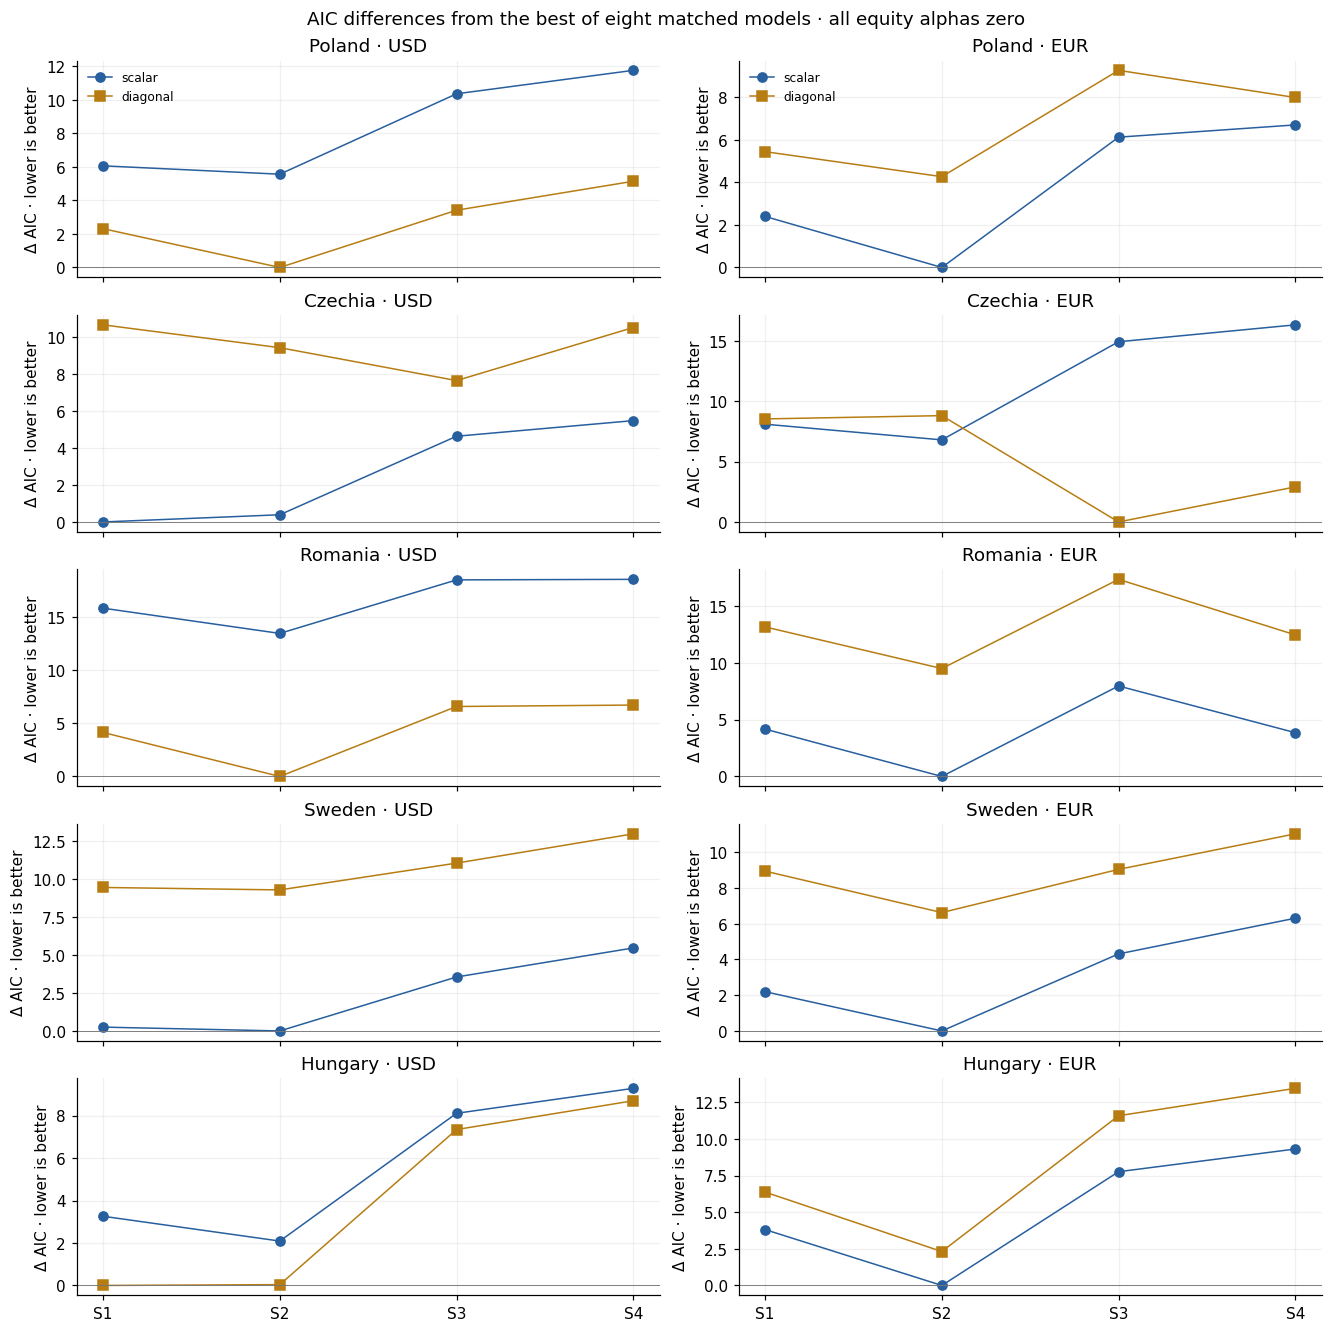

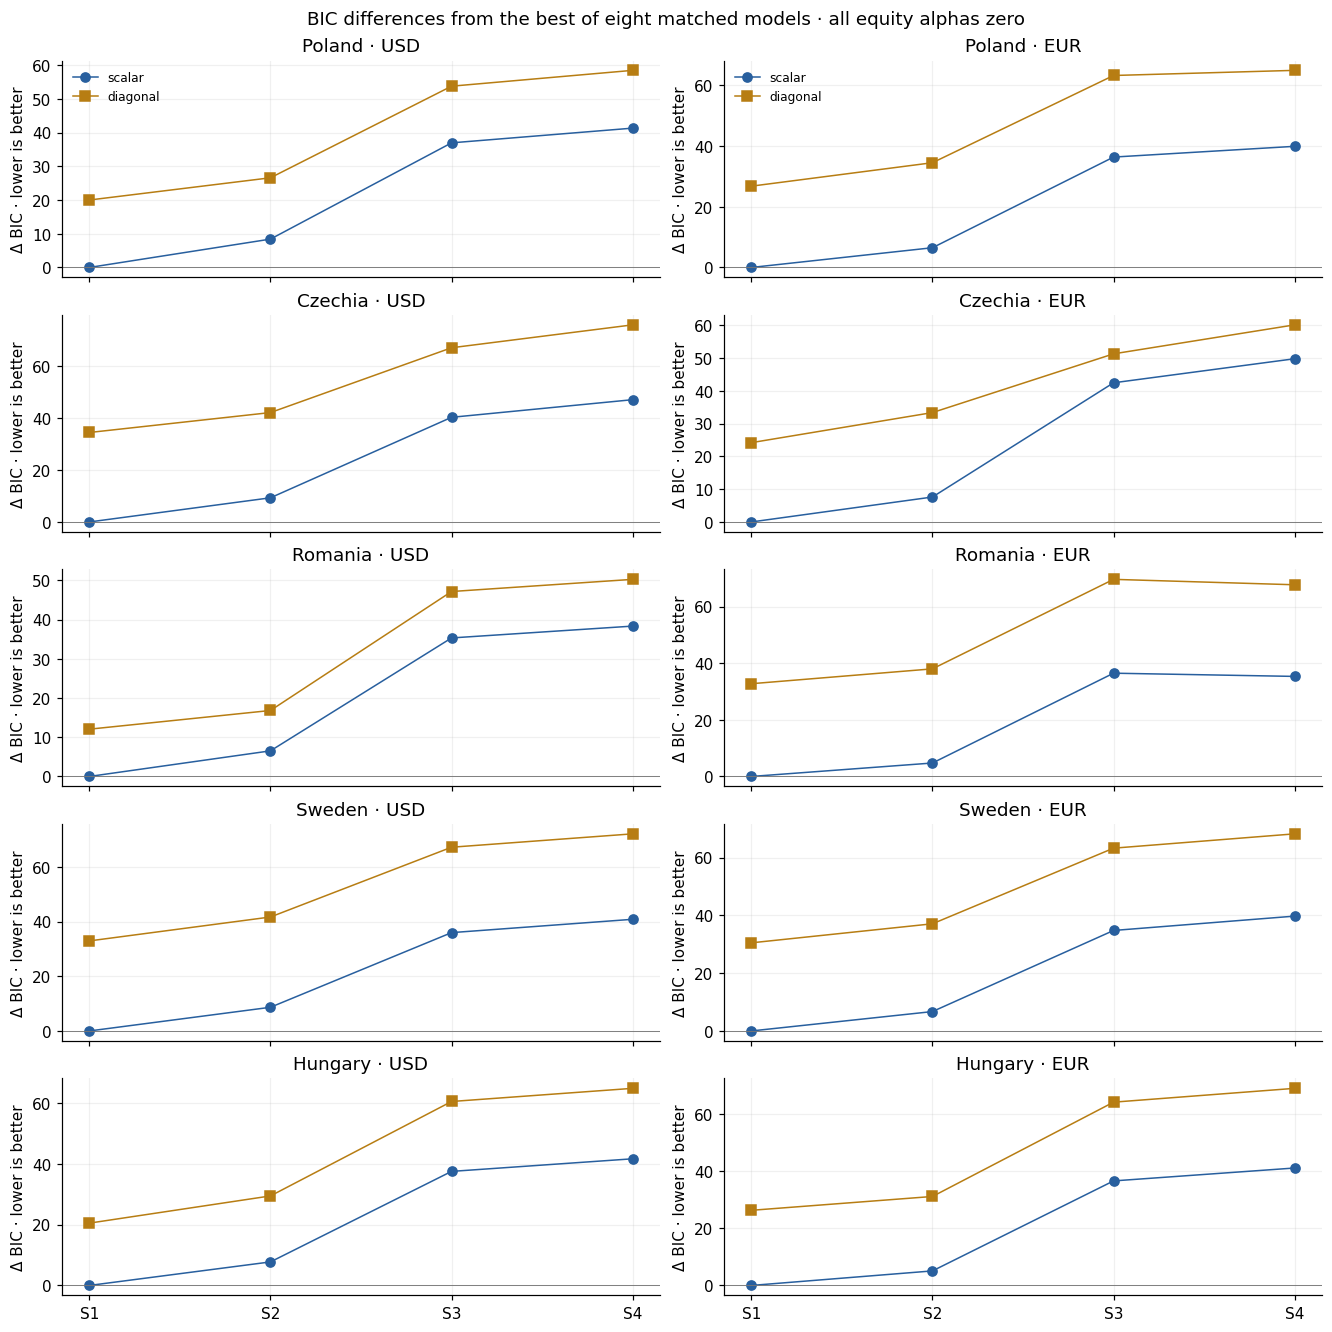

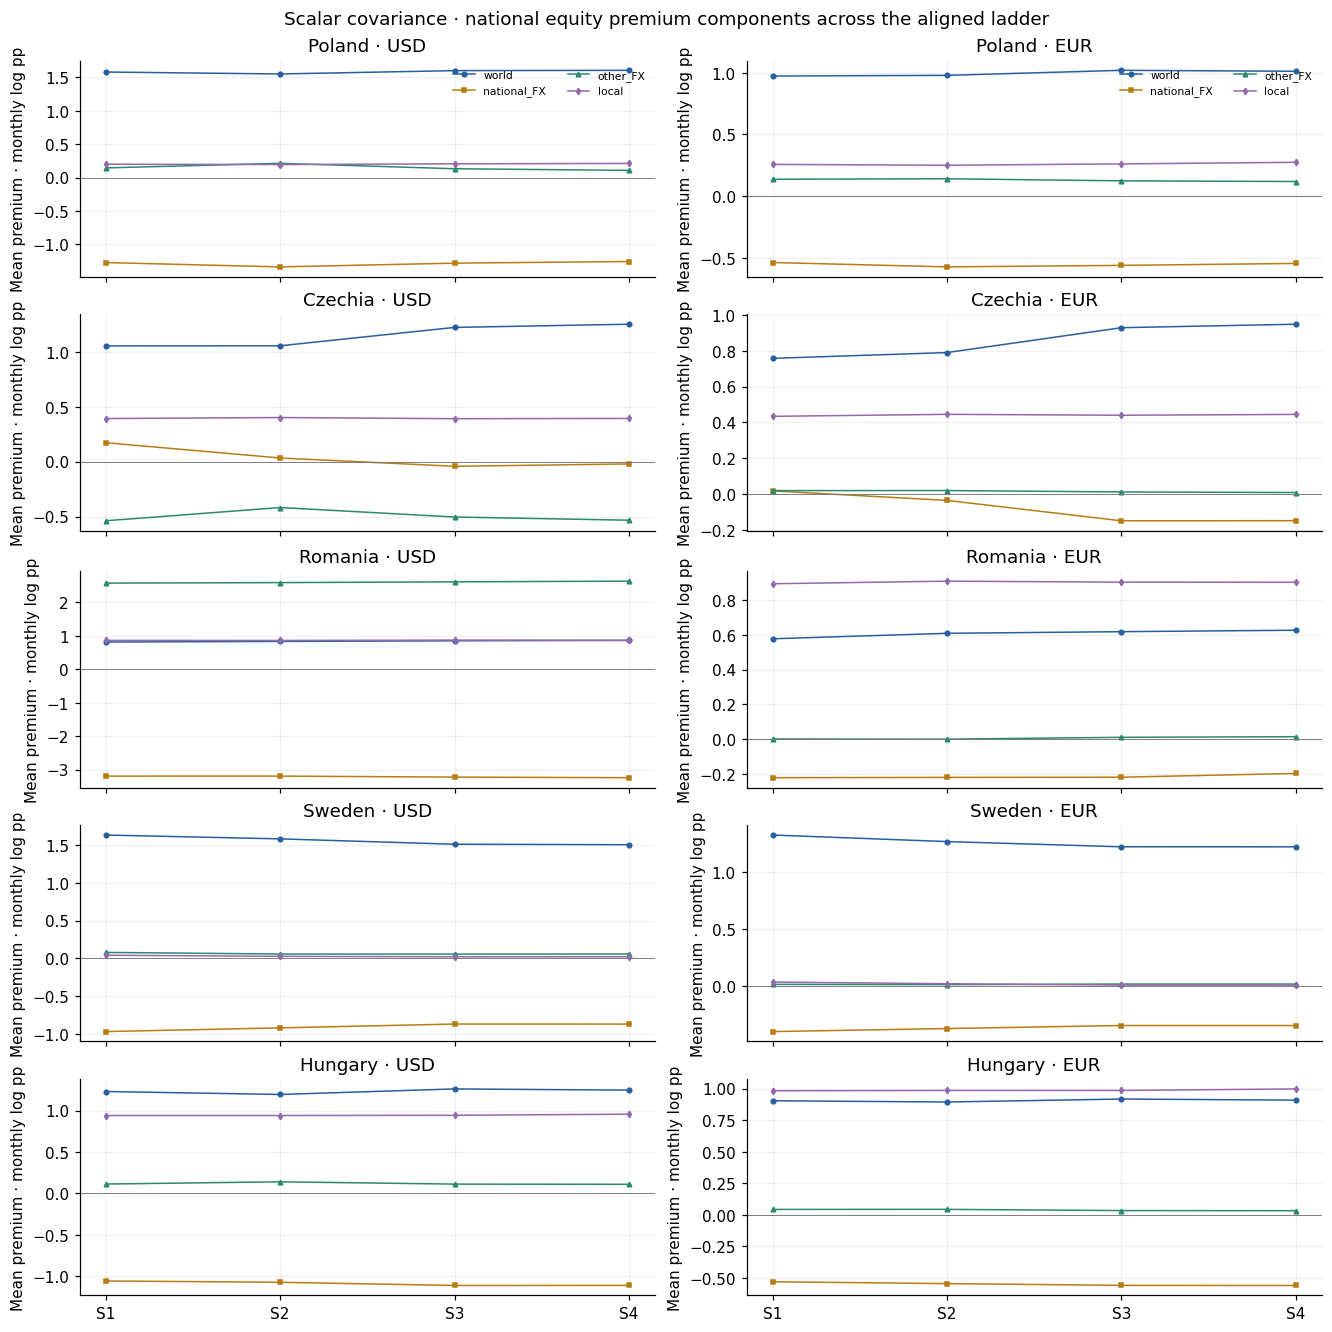

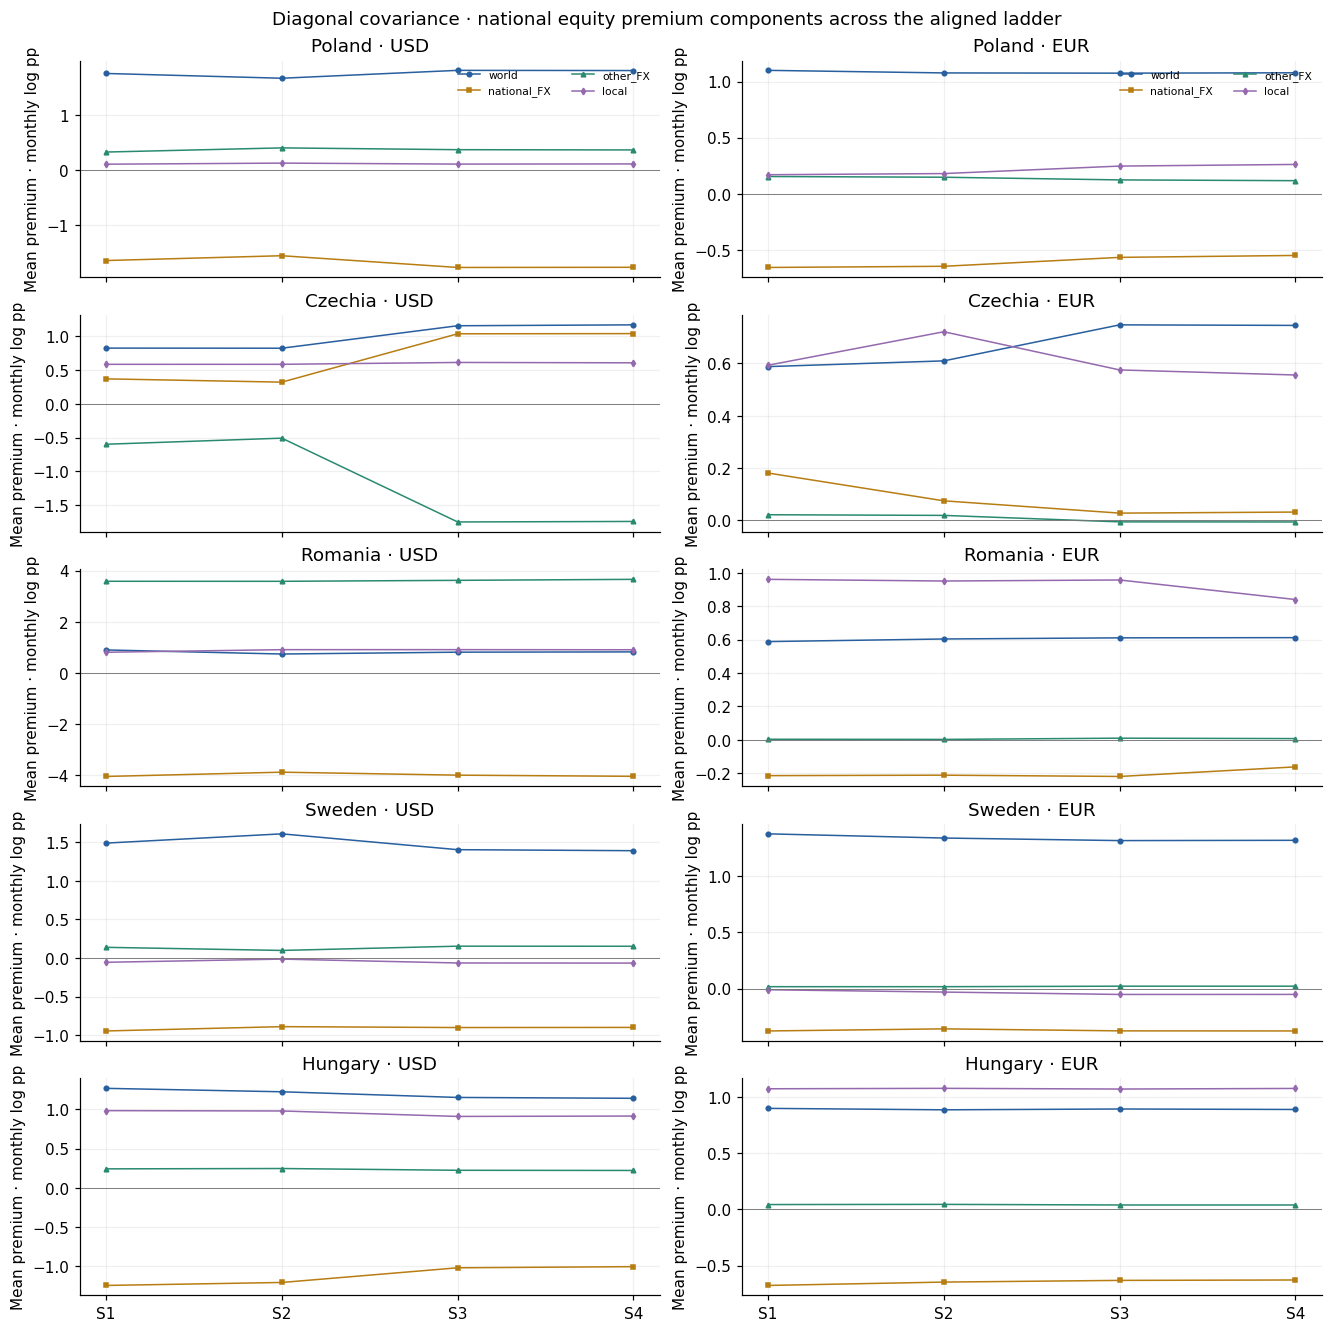

In [8]:
premium_rows, product_rows = [], []
for key, fit in fits.items():
    country, currency, covariance, stage = key; f = fit["filter"]
    prices = {"world": f["world_prices"], "national_FX": f["fx_prices"][:, 0], "other_FX": f["fx_prices"][:, 1], "local": f["local_prices"]}
    covs = {"world": f["H"][:, 2, 0], "national_FX": f["H"][:, 2, 3], "other_FX": f["H"][:, 2, 4], "local": f["H"][:, 2, 2]}
    components = {a: prices[a]*covs[a] for a in prices}; total = sum(components.values())
    np.testing.assert_allclose(total, f["mu"][:, 2], atol=1e-11, rtol=0)
    tags = {"country": country, "perspective": currency, "covariance": covariance, "stage": stage}
    for a, j in [("world", 0), ("national_FX", 3), ("other_FX", 4), ("local", 2)]:
        np.testing.assert_allclose(prices[a].mean(), engine.PRICE_SCALE*fit["theta"][j], atol=1e-12, rtol=0)
        product_rows.append({**tags, "component": a, "mean_risk_price": prices[a].mean(), "mean_covariance_pp2": covs[a].mean(),
            "mean_contribution_pp": components[a].mean(), "product_of_means_pp": prices[a].mean()*covs[a].mean(),
            "price_covariance_interaction_pp": components[a].mean()-prices[a].mean()*covs[a].mean()})
    premium_rows.extend({**tags, "month": str(month), **{a+"_price": v[t] for a, v in prices.items()},
        **{a+"_covariance_pp2": v[t] for a, v in covs.items()}, **{a+"_premium_pp": v[t] for a, v in components.items()},
        "fitted_mean_pp": total[t], "equity_alpha_pp": 0.} for t, month in enumerate(months))
premiums, product_summary = pd.DataFrame(premium_rows), pd.DataFrame(product_rows)
for criterion in ["AIC", "BIC"]:
    fig, axes = plt.subplots(5, 2, figsize=(12, 12), sharex=True, layout="constrained")
    for row, country in enumerate(NAMES):
        for col, currency in enumerate(CURRENCIES):
            ax = axes[row, col]
            for covariance, marker, color in [("scalar", "o", "#285f9e"), ("diagonal", "s", "#b77d13")]:
                g = comparison.query("country == @country and perspective == @currency and covariance == @covariance").sort_values("stage")
                ax.plot(g.stage, g["delta_"+criterion+"_best"], marker=marker, color=color, lw=1, label=covariance)
            ax.axhline(0, color="#777777", lw=.6); ax.set(title=f"{NAMES[country]} · {currency}", ylabel=f"Δ {criterion} · lower is better", xticks=[1,2,3,4], xticklabels=["S1","S2","S3","S4"])
            if row == 0: ax.legend(frameon=False, fontsize=8)
    fig.suptitle(f"{criterion} differences from the best of eight matched models · all equity alphas zero")
    save_plot(f"01_{criterion}_comparison.png")
for covariance in COVARIANCES:
    fig, axes = plt.subplots(5, 2, figsize=(12, 12), sharex=True, layout="constrained")
    for row, country in enumerate(NAMES):
        for col, currency in enumerate(CURRENCIES):
            ax = axes[row, col]
            for component, marker, color in [("world", "o", "#285f9e"), ("national_FX", "s", "#b77d13"), ("other_FX", "^", "#2a8a70"), ("local", "d", "#9469ad")]:
                g = product_summary.query("country == @country and perspective == @currency and covariance == @covariance and component == @component").sort_values("stage")
                ax.plot(g.stage, g.mean_contribution_pp, marker=marker, ms=3, color=color, lw=1, label=component)
            ax.axhline(0, color="#777777", lw=.6); ax.set(title=f"{NAMES[country]} · {currency}", ylabel="Mean premium · monthly log pp", xticks=[1,2,3,4], xticklabels=["S1","S2","S3","S4"])
            if row == 0: ax.legend(frameon=False, fontsize=7, ncol=2)
    fig.suptitle(f"{covariance.capitalize()} covariance · national equity premium components across the aligned ladder")
    save_plot(f"02_premium_components_{covariance}.png")

## 8. Final common-sample comparison and reproducibility

Read the criterion winners alongside numerical inference and residual adequacy. Information-criterion
preference is not a pricing test or a guarantee of stable estimates. Retain the common 144-month
Hungarian comparison; do not substitute its longer historical fit. The four-stage sequence is only
this candidate set; subsequent FX-only time-variation and targeted robustness branches remain research
extensions. Snapshot timing, index/ETF proxies, persistent conditioners, crisis influence, short-sample
uncertainty and covariance misspecification still qualify any economic interpretation.

In [9]:
display(winners.set_index(["name", "perspective", "criterion"]).round(5))
display(comparison.set_index(["country", "perspective", "covariance", "stage"])[["parameters", "loglik", "AIC_rank_all8", "BIC_rank_all8", "delta_AIC_best", "delta_BIC_best", "inference_ready_QML"]].round(5))
tables = {"input_audit.csv": input_audit, "source_design_audit.csv": source_design_audit, "design_audit.csv": design_audit,
    "conditioning_design.csv": conditioning, "instrument_transform.csv": transform_table, "inflation_quality_flags.csv": quality_flags,
    "reference_audit.csv": reference_audit, "implementation_checks.csv": checks, "candidate_audit.csv": candidate_audit,
    "refinements.csv": refinements, "starting_points.csv": starting_points, "nesting_audit.csv": nesting_audit,
    "fit_summary.csv": fit_table, "restriction_tests.csv": tests, "price_coefficients.csv": price_coefficients,
    "inference_audit.csv": inference_audit, "parameter_bounds.csv": parameter_bounds, "risk_price_paths.csv": price_paths,
    "residual_diagnostics.csv": residuals, "cross_covariance_diagnostics.csv": cross, "diagnostic_summary.csv": diagnostic_summary,
    "model_comparison.csv": comparison, "criterion_winners.csv": winners, "premium_components.csv": premiums,
    "price_covariance_products.csv": product_summary}
for name, frame in tables.items(): frame.to_csv(OUT/name, index=False, float_format="%.17g", lineterminator=chr(10))
parameter_files = []
for key, fit in fits.items():
    case = cases[key]; f = fit["filter"]; name = f"parameters_{case['id']}.npz"
    np.savez(OUT/name, theta=fit["theta"], H=f["H"], mu=f["mu"], errors=f["errors"], scores=f["scores"],
        equity_alphas=np.zeros(3), target=f["target"], intercept=f["intercept"], Hessian=fit["inference"]["Hessian"],
        **{f"covariance_HAC{h}": e["covariance"] for h, e in fit["inference"]["estimates"].items()})
    parameter_files.append(name)
_, after = verify_inputs()
assert input_hashes == after and engine_hashes == {n: sha((ROOT/n).read_bytes()) for n in engine_hashes}
outputs = [*tables, *figure_files, *parameter_files, *refinement_files]
metadata = {"notebook": "28_regional_final_model_comparison.ipynb", "model_version": MODEL_VERSION, "engines": engine_hashes,
    "previous_manifest_sha256": PREVIOUS_MANIFEST_SHA, "first": str(months[0]), "last": str(months[-1]), "observations_per_fit": len(months),
    "verified_fits": len(references), "comparison_cases": len(fits), "refined_cases": int(sum(f["refinement_rounds"] > 0 for f in fits.values())),
    "refinement_events": len(refinements), "final_audit_sweep": sweep, "input_locks": LOCK_HASHES, "input_file_hashes": input_hashes,
    "spec": spec, "source_locations": {str(s): {"folder": p.relative_to(ROOT).as_posix(), "suffix": suffix} for s, (p, suffix) in SOURCES.items()},
    "settings": {"START_DYNAMICS": START_DYNAMICS, "MAX_ITER": MAX_ITER, "MAX_ITER_OVERRIDES": {"/".join(map(str,k)): v for k,v in MAX_ITER_OVERRIDES.items()},
        "MAX_AUDIT_SWEEPS": MAX_AUDIT_SWEEPS, "CANDIDATE_TOL": CANDIDATE_TOL, "TEST_LAGS": TEST_LAGS, "HAC_LAGS": HAC_LAGS},
    "python": sys.executable, "python_version": platform.python_version(), "packages": versions,
    "outputs": {name: sha((OUT/name).read_bytes()) for name in outputs},
    "notes": ["Four nested pricing stages, scalar/diagonal BEKK, five countries, USD/EUR; common frozen 144 months",
        "Corrected priced FX means and structurally zero equity alphas in all 80 cases; US local price constant",
        "References verified, all tested feasible mappings audited, only demonstrated improvements refined in this output folder",
        "Existing free positive covariance intercept and stationary innovation initialization retained",
        "Full joint QML/HAC 0/3/6/12; invalid inference suppressed; pricing tests exploratory/unadjusted",
        "AIC/BIC ranks within country/investor over all eight candidates; numerical and residual flags retained",
        "Means of monthly price-covariance products; no alpha or hedging-cost component"]}
(OUT/"estimation_manifest.json").write_text(json.dumps(metadata, indent=2, sort_keys=True)+chr(10))
display(winners.groupby(["criterion", "stage", "covariance"]).size().rename("country/investor winners"))
display(Markdown(f"**Completed:** {len(fits)} aligned zero-alpha cases, {len(references)} verified references and "
    f"**{metadata['refined_cases']}** refined cases; **{months[0]}–{months[-1]} ({len(months)} months)** in base. "
    f"Saved {len(tables)} tables and {len(figure_files)} charts in `{OUT.relative_to(ROOT)}`. "
    "All frozen inputs and earlier outputs remain unchanged; criterion winners still require numerical and diagnostic qualification."))

country  stage       stage_name covariance  \
name    perspective criterion                                              
Hungary USD         AIC            HU      1  Constant prices   diagonal   
                    BIC            HU      1  Constant prices     scalar   
        EUR         AIC            HU      2         TV world     scalar   
                    BIC            HU      1  Constant prices     scalar   
Poland  USD         AIC            PL      2         TV world   diagonal   
                    BIC            PL      1  Constant prices     scalar   
        EUR         AIC            PL      2         TV world     scalar   
                    BIC            PL      1  Constant prices     scalar   
Czechia USD         AIC            CZ      1  Constant prices     scalar   
                    BIC            CZ      1  Constant prices     scalar   
        EUR         AIC            CZ      3    TV world + FX   diagonal   
                    BIC            CZ      1  Constant prices     scalar   
Romania USD         AIC            RO      2         TV world   diagonal   
                    BIC            RO      1  Constant prices     scalar   
        EUR         AIC            RO      2         TV world     scalar   
                    BIC            RO      1  Constant prices     scalar   
Sweden  USD         AIC            SE      2         TV world     scalar   
                    BIC            SE      1  Constant prices     scalar   
        EUR         AIC            SE      2         TV world     scalar   
                    BIC            SE      1  Constant prices     scalar   

                               criterion_value  inference_ready_QML  \
name    perspective criterion                                         
Hungary USD         AIC             3200.50799                False   
                    BIC             3269.10297                 True   
        EUR         AIC             3199.10030                 True   
                    BIC             3268.25264                 True   
Poland  USD         AIC             3048.31840                False   
                    BIC             3119.71875                 True   
        EUR         AIC             3051.31409                 True   
                    BIC             3119.05190                 True   
Czechia USD         AIC             2947.72174                 True   
                    BIC             3013.05763                 True   
        EUR         AIC             2938.85540                False   
                    BIC             3012.28744                 True   
Romania USD         AIC             2849.84858                False   
                    BIC             2931.02688                 True   
        EUR         AIC             2860.78534                 True   
                    BIC             2930.28384                 True   
Sweden  USD         AIC             2991.98783                 True   
                    BIC             3057.57554                 True   
        EUR         AIC             2989.85785                 True   
                    BIC             3057.39126                 True   

                                                     inference_reason_QML  \
name    perspective criterion                                               
Hungary USD         AIC        parameter bound; ill-conditioned curvature   
                    BIC                                 numerically ready   
        EUR         AIC                                 numerically ready   
                    BIC                                 numerically ready   
Poland  USD         AIC        parameter bound; ill-conditioned curvature   
                    BIC                                 numerically ready   
        EUR         AIC                                 numerically ready   
                    BIC                                 numerically ready   
Czechia USD         AIC 

parameters      loglik  AIC_rank_all8  \
country perspective covariance stage                                          
HU      USD         scalar     1              22 -1579.88354              4   
                               2              25 -1576.29927              3   
                               3              33 -1571.30830              6   
                               4              34 -1570.89607              8   
                    diagonal   1              30 -1570.25400              1   
...                                          ...         ...            ...   
SE      EUR         scalar     4              34 -1464.08331              4   
                    diagonal   1              30 -1469.40001              6   
                               2              33 -1465.24062              5   
                               3              41 -1458.44930              7   
                               4              42 -1458.44315              8   

                                      BIC_rank_all8  delta_AIC_best  \
country perspective covariance stage                                  
HU      USD         scalar     1                  1         3.25909   
                               2                  2         2.09054   
                               3                  5         8.10861   
                               4                  6         9.28415   
                    diagonal   1                  3         0.00000   
...                                             ...             ...   
SE      EUR         scalar     4                  6         6.30877   
                    diagonal   1                  3         8.94217   
                               2                  5         6.62339   
                               3                  7         9.04075   
                               4                  8        11.02844   

                                      delta_BIC_best  inference_ready_QML  
country perspective covariance stage                                       
HU      USD         scalar     1             0.00000                 True  
                               2             7.74089                 True  
                               3            37.51747                 True  
                               4            41.66282                 True  
                    diagonal   1            20.49942                False  
...                                              ...                  ...  
SE      EUR         scalar     4            39.74901                 True  
                    diagonal   1            30.50315                 True  
                               2            37.09382                False  
                               3            63.26969                False  
                               4            68.22719                False  

[80 rows x 7 columns]

criterion  stage  covariance
AIC        1      diagonal       1
                  scalar         1
           2      diagonal       2
                  scalar         5
           3      diagonal       1
BIC        1      scalar        10
Name: country/investor winners, dtype: int64

**Completed:** 80 aligned zero-alpha cases, 80 verified references and **2** refined cases; **2014-10–2026-09 (144 months)** in base. Saved 25 tables and 4 charts in `output/28_regional_final_model_comparison/2014-10_2026-09/aligned_4e92b411`. All frozen inputs and earlier outputs remain unchanged; criterion winners still require numerical and diagnostic qualification.